# Project 2 noahs

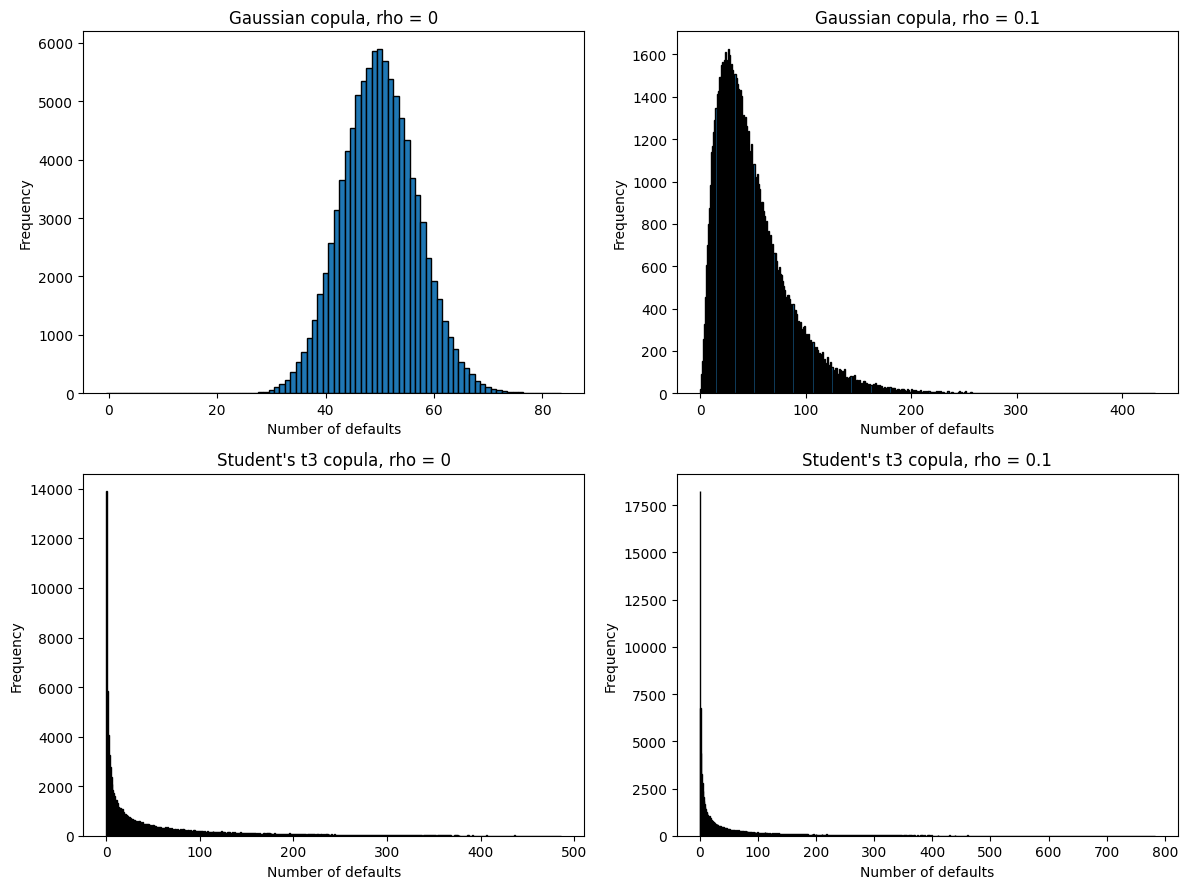

In [ ]:
#Given code for Example 9.20 in the book, transformed into Python from R
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Example 9.20: Default risk

N = 10**5
n = 1000
defr = 3
depr = 0.05
runlen = 1000

np.random.seed(37)

# Correlation matrices
covmat1 = np.eye(n)
covmat2 = 0.9 * np.eye(n) + 0.1 * np.ones((n, n))

cholmat = np.linalg.cholesky(covmat2)

# Store number of defaults for each model
resmat = np.zeros((4, N), dtype=int)

# Default thresholds
q1 = stats.norm.ppf(depr)
q2 = stats.t.ppf(depr, df=defr)

for i in range(N // runlen):

    # Radial variables for Student's t copula
    radialvals = np.sqrt(defr) / np.sqrt(np.random.chisquare(defr, size=runlen))

    # Independent standard normal observations
    normsampledata = np.random.multivariate_normal(np.zeros(n), covmat1, size=runlen)

    for j in range(runlen):

        Z = normsampledata[j, :]
        Z_corr = cholmat @ Z

        # (a) Gaussian copula, rho = 0
        resmat[0, i * runlen + j] = np.sum(Z < q1)

        # (b) Gaussian copula, rho = 0.1
        resmat[1, i * runlen + j] = np.sum(Z_corr < q1)

        # (c) Student's t3 copula, rho = 0
        resmat[2, i * runlen + j] = np.sum(radialvals[j] * Z < q2)

        # (d) Student's t3 copula, rho = 0.1
        resmat[3, i * runlen + j] = np.sum(radialvals[j] * Z_corr < q2)


# Histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

titles = [
    "Gaussian copula, rho = 0",
    "Gaussian copula, rho = 0.1",
    "Student's t3 copula, rho = 0",
    "Student's t3 copula, rho = 0.1"
]

for ax, data, title in zip(axes.flat, resmat, titles):
    ax.hist(data, bins=np.arange(data.max() + 2) - 0.5,
            edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Number of defaults")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Example 9.20: Default risk

N = 10**5
n = 1000
defr = 3
depr = 0.03
runlen = 1000

np.random.seed(37)

# Correlation matrices
covmat1 = np.eye(n)                               # rho = 0
covmat2 = 0.9 * np.eye(n) + 0.1 * np.ones((n,n))  # rho = 0.1
covmat3 = 0.5 * np.eye(n) + 0.5 * np.ones((n,n))  # rho = 0.5
covmat4 = 0.1 * np.eye(n) + 0.9 * np.ones((n,n))  # rho = 0.9

cholmat2 = np.linalg.cholesky(covmat2)
cholmat3 = np.linalg.cholesky(covmat3)
cholmat4 = np.linalg.cholesky(covmat4)

# Store number of defaults for each model
resmat2 = np.zeros((4, N), dtype=int)

# Default thresholds
q1 = stats.norm.ppf(depr)
q2 = stats.t.ppf(depr, df=defr)

for i in range(N // runlen):

    # Radial variables for Student's t copula
    radialvals = np.sqrt(defr) / np.sqrt(np.random.chisquare(defr, size=runlen))

    # Independent standard normal observations
    normsampledata = np.random.multivariate_normal(np.zeros(n), covmat1, size=runlen)

    for j in range(runlen):

        Z = normsampledata[j, :]

        Z_corr3 = cholmat3 @ Z
        Z_corr4 = cholmat4 @ Z

        # (e) Gaussian copula, rho = 0.5
        resmat2[1, i * runlen + j] = np.sum(Z_corr3 < q1)

        # (f) Gaussian copula, rho = 0.9
        resmat2[2, i * runlen + j] = np.sum(Z_corr4 < q1)

        # (g) Student's t3 copula, rho = 0.5
        resmat2[3, i * runlen + j] = np.sum(radialvals[j] * Z_corr3 < q2)

        # (h) Student's t3 copula, rho = 0.9
        resmat2[4, i * runlen + j] = np.sum(radialvals[j] * Z_corr4 < q2)



# Histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

titles = [
    "Gaussian copula, rho = 0",
    "Gaussian copula, rho = 0.1",
    "Student's t3 copula, rho = 0",
    "Student's t3 copula, rho = 0.1"
]

for ax, data, title in zip(axes.flat, resmat, titles):
    ax.hist(data, bins=np.arange(data.max() + 2) - 0.5,
            edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Number of defaults")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()
